<a href="https://colab.research.google.com/github/naarsara/ANTIBIOTIC-SUSCEPTIBILITY-SARA-IA/blob/main/TP02_IA_SARA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# Define the file path from your Google Drive
file_path = '/content/drive/MyDrive/TP02 IA SARA/Dataset on Antibiotic susceptibility patterns of Gram negative uropathogens from patients in a tertiary hospital in South west Nigeria.xlsx'

# Read the Excel file
# We'll use pd.read_excel and inspect the sheet names first to make sure we load the correct data
xls = pd.ExcelFile(file_path)
print("Available sheets:", xls.sheet_names)

# Load the first sheet into a DataFrame
df = xls.parse(xls.sheet_names[0])

# Display basic information and the first few rows
print(f"\nDataset shape: {df.shape}")
display(df.head())

Available sheets: ['Sheet1', 'Sheet2', 'Sheet3']

Dataset shape: (3612, 28)


,S\N,SEX,WARD\CLINIC,SPECIMEN,CULTURE,Unnamed: 5,ORGANISM,AMOXYCILLIN CLAVULANATE SENSITIVE,AMOXYCILLIN CLAVULANATE INTERMEDIATE,AMOXYCILLIN CLAVULANATE RESISTANT,...,MEROPENEMRESISTANT,NITROFURANTOIN SENSITIVE,NITROFURANTOIN INTERMEDIATE,NITROFURANTOIN RESISTANT,PIP TAZOBACTAM SENSITIVE,PIP TAZOBACTAM INTERMEDIATE,PIP TAZOBACTAM RESISTANT,CEFTRIAXONE SENSITIVE,CEFTRIAXONE INTERMEDIATE,CEFTRIAXONE RESISTANT
0,1,M,Outpatient,Urine,Positive,NaN,Klebsiella sp,S,NaN,,...,NaN,S,NaN,NaN,S,NaN,NaN,NaN,NaN,NaN
1,2,M,Outpatient,Urine,Positive,NaN,Klebsiella sp,S,NaN,NaN,...,NaN,S,NaN,NaN,S,NaN,NaN,NaN,NaN,NaN
2,3,M,Outpatient,Urine,Positive,NaN,Klebsiella sp,S,NaN,NaN,...,NaN,S,NaN,NaN,S,NaN,NaN,NaN,NaN,NaN
3,4,M,Outpatient,Urine,Positive,NaN,Klebsiella sp,S,NaN,NaN,...,NaN,S,NaN,NaN,S,NaN,NaN,NaN,NaN,NaN
4,5,M,Outpatient,Urine,Positive,NaN,Klebsiella sp,S,NaN,NaN,...,NaN,S,NaN,NaN,S,NaN,NaN,NaN,NaN,NaN


### Identification des Variables (X et Y)

Pour préparer notre modèle ou notre analyse, nous devons explorer la structure des colonnes afin de distinguer :
- **Les variables explicatives (X)** : caractéristiques des patients (genre, âge, service/clinique, etc.).
- **Les variables cibles / à prédire (Y)** : la présence de bactéries spécifiques ou les profils de sensibilité/résistance aux différents antibiotiques.

In [ ]:
import pandas as pd

# 1. Afficher toutes les colonnes disponibles et leurs types
print("--- Liste de toutes les colonnes et types de données ---")
display(df.dtypes)

# 2. Inspecter les valeurs uniques pour les colonnes de base (potentiels X)
# Utilisation de chaînes brutes (r'...') pour éviter les erreurs d'échappement avec la barre oblique inversée
candidats_X = ['SEX', r'WARD\CLINIC', 'SPECIMEN', 'CULTURE']
print("\n--- Exploration des variables indépendantes potentielles (X) ---")
for col in candidats_X:
    if col in df.columns:
        print(f"\nValeurs uniques pour '{col}' (Top 10) :")
        print(df[col].value_counts().head(10))

# 3. Identifier les colonnes d'antibiotiques (potentiels Y)
# Utilisation de r'S\N' pour éviter l'erreur d'échappement Unicode de \N
antibiotiques_cols = [col for col in df.columns if col not in candidats_X and col != r'S\N']
print("\n--- Variables dépendantes potentielles (Y : Susceptibilité aux Antibiotiques) ---")
print(f"Nombre d'antibiotiques détectés : {len(antibiotiques_cols)}")
print("Liste des antibiotiques / profils de résistance détectés :")
print(antibiotiques_cols)

--- Liste de toutes les colonnes et types de données ---


,0
S\N,object
SEX,object
WARD\CLINIC,object
SPECIMEN,object
CULTURE,object
Unnamed: 5,float64
ORGANISM,object
AMOXYCILLIN CLAVULANATE SENSITIVE,object
AMOXYCILLIN CLAVULANATE INTERMEDIATE,object
AMOXYCILLIN CLAVULANATE RESISTANT,object



--- Exploration des variables indépendantes potentielles (X) ---

Valeurs uniques pour 'SEX' (Top 10) :
SEX
F    2273
M    1339
Name: count, dtype: int64

Valeurs uniques pour 'WARD\CLINIC' (Top 10) :
WARD\CLINIC
Outpatient    2119
In-patient    1493
Name: count, dtype: int64

Valeurs uniques pour 'SPECIMEN' (Top 10) :
SPECIMEN
urine    2993
Urine     619
Name: count, dtype: int64

Valeurs uniques pour 'CULTURE' (Top 10) :
CULTURE
Negative    2804
Positive     807
positive       1
Name: count, dtype: int64

--- Variables dépendantes potentielles (Y : Susceptibilité aux Antibiotiques) ---
Nombre d'antibiotiques détectés : 23
Liste des antibiotiques / profils de résistance détectés :
['Unnamed: 5', 'ORGANISM', 'AMOXYCILLIN CLAVULANATE SENSITIVE', 'AMOXYCILLIN CLAVULANATE INTERMEDIATE', 'AMOXYCILLIN CLAVULANATE RESISTANT', 'CEFTAZIDIME SENSITIVE', 'CEFTAZIDIME INTERMEDIATE', 'CEFTAZIDIME RESISTANT', 'CIPROFLOXACIN SENSITIVE', 'CIPROFLOXACIN INTERMEDIATE', 'CIPROFLOXACINRESISTANT', 'MEROP

### Analyse de la relation entre X (Caractéristiques) et Y (Résultats de Culture/Organismes)

Pour mieux comprendre notre jeu de données, nous allons croiser nos variables explicatives ($X$) avec nos variables d'intérêt ($Y$) :
1. **Relation Genre (SEX) vs Culture (CULTURE)**.
2. **Relation Service Hospitalier (WARD\CLINIC) vs Culture (CULTURE)**.
3. **Distribution des organismes identifiés ($Y$) selon le Genre ($X$)**.

=== Relation entre le Genre (X) et le résultat de la Culture (Y) ===


CULTURE,Negative,Positive,All
SEX,,,
F,1761,512,2273
M,1043,296,1339
All,2804,808,3612



=== Relation entre le Service (X) et le résultat de la Culture (Y) ===


CULTURE,Negative,Positive,All
WARD\CLINIC,,,
In-patient,907,586,1493
Outpatient,1897,222,2119
All,2804,808,3612


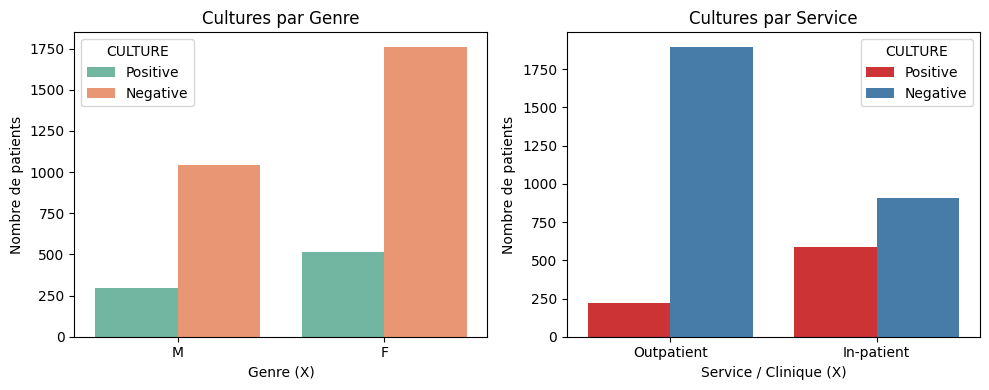

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Nettoyage rapide pour uniformiser les données textuelles (ex: Urine vs urine, Positive vs positive)
if 'SPECIMEN' in df.columns:
    df['SPECIMEN'] = df['SPECIMEN'].str.strip().str.capitalize()
if 'CULTURE' in df.columns:
    df['CULTURE'] = df['CULTURE'].str.strip().str.capitalize()
if 'SEX' in df.columns:
    df['SEX'] = df['SEX'].str.strip().str.upper()

# 1. Tableau croisé : SEX vs CULTURE
print("=== Relation entre le Genre (X) et le résultat de la Culture (Y) ===")
ct_sex_culture = pd.crosstab(df['SEX'], df['CULTURE'], margins=True)
display(ct_sex_culture)

# 2. Tableau croisé : WARD\CLINIC vs CULTURE
print("\n=== Relation entre le Service (X) et le résultat de la Culture (Y) ===")
if r'WARD\CLINIC' in df.columns:
    ct_ward_culture = pd.crosstab(df[r'WARD\CLINIC'], df['CULTURE'], margins=True)
    display(ct_ward_culture)

# 3. Visualisation de la répartition des cultures par Genre
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='SEX', hue='CULTURE', palette='Set2')
plt.title('Cultures par Genre')
plt.xlabel('Genre (X)')
plt.ylabel('Nombre de patients')

# Visualisation de la répartition par Service
plt.subplot(1, 2, 2)
if r'WARD\CLINIC' in df.columns:
    sns.countplot(data=df, x=r'WARD\CLINIC', hue='CULTURE', palette='Set1')
    plt.title('Cultures par Service')
    plt.xlabel('Service / Clinique (X)')
    plt.ylabel('Nombre de patients')

plt.tight_layout()
plt.show()